In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(
    style="whitegrid"
)

pd.set_option(
    "display.max_columns",
    100,
)

In [3]:
# Configure paths and verify artifacts
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
REPORT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "reports"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "evaluation"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
paths = {
    "baseline_metrics": (
        REPORT_DIR
        / "baseline_model_metrics.csv"
    ),

    "baseline_predictions": (
        REPORT_DIR
        / "baseline_test_predictions.csv"
    ),

    "advanced_validation": (
        REPORT_DIR
        / "advanced_validation_metrics.csv"
    ),

    "advanced_test": (
        REPORT_DIR
        / "advanced_test_metrics.csv"
    ),

    "advanced_predictions": (
        REPORT_DIR
        / "advanced_test_predictions.csv"
    ),

    "prophet_validation": (
        REPORT_DIR
        / "prophet_validation_metrics.csv"
    ),

    "prophet_test": (
        REPORT_DIR
        / "prophet_test_metrics.csv"
    ),

    "prophet_predictions": (
        REPORT_DIR
        / "prophet_test_predictions.csv"
    ),
}
missing_files = [
    str(path)
    for path in paths.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing artifacts:\n"
        + "\n".join(missing_files)
    )

print(
    "All artifacts were found."
)

All artifacts were found.


In [4]:
# Load and standardize validation metrics
REQUIRED_METRICS = ['model', 'split', 'MAE', 'RMSE', 'MAPE_pct', 'R2']

def standardize_metrics(frame, default_model=None, default_split=None):
    frame = frame.copy()
    frame.columns = frame.columns.str.strip()
    rename = {
        'mae': 'MAE', 'rmse': 'RMSE', 'mape': 'MAPE_pct',
        'mape_pct': 'MAPE_pct', 'r2': 'R2', 'Model': 'model', 'Split': 'split',
    }
    frame = frame.rename(columns=rename)
    if 'model' not in frame and default_model:
        frame['model'] = default_model
    if 'split' not in frame and default_split:
        frame['split'] = default_split
    missing_columns = set(REQUIRED_METRICS) - set(frame.columns)
    if missing_columns:
        raise KeyError(f'Missing metric columns: {sorted(missing_columns)}')
    return frame[REQUIRED_METRICS]

baseline = standardize_metrics(pd.read_csv(paths['baseline_metrics']))
advanced_validation = standardize_metrics(
    pd.read_csv(paths['advanced_validation']), default_split='validation'
)
prophet_validation = standardize_metrics(
    pd.read_csv(paths['prophet_validation']), default_model='Prophet', default_split='validation'
)
validation_metrics = pd.concat([
    baseline.query("split == 'validation'"), advanced_validation, prophet_validation
], ignore_index=True).drop_duplicates(subset=['model', 'split'], keep='last')
validation_metrics = validation_metrics.sort_values(['RMSE', 'MAE']).reset_index(drop=True)
validation_metrics.round(3)

,model,split,MAE,RMSE,MAPE_pct,R2
0,Prophet,validation,8096.652,10787.230,39.758,0.511
1,Random Forest,validation,7847.410,10793.128,40.877,0.511
2,XGBoost,validation,7776.941,10841.431,40.286,0.506
3,Linear Regression,validation,9528.868,12752.753,38.241,0.317
4,Moving average 7,validation,12445.578,15881.538,52.130,-0.060
5,Naive lag-1,validation,15208.789,18422.141,65.458,-0.426


In [5]:
# Select the model without looking at test
# Primary metric: RMSE. Tie-breaker: MAE. MAPE is supporting evidence because zero/negative net revenue can make percentage errors unstable.
assert np.isfinite(validation_metrics[['MAE', 'RMSE']].to_numpy()).all()
selected_model = validation_metrics.iloc[0]['model']
selected_validation_rmse = float(validation_metrics.iloc[0]['RMSE'])
print('Selected model:', selected_model)
print('Validation RMSE:', round(selected_validation_rmse, 3))

Selected model: Prophet
Validation RMSE: 10787.23


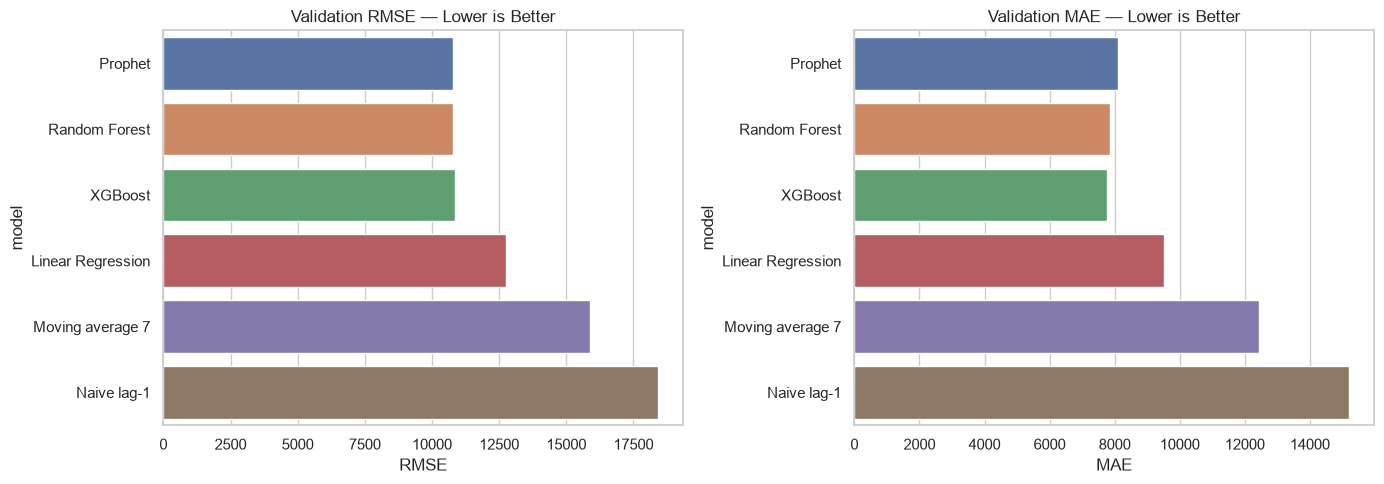

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=validation_metrics, x='RMSE', y='model', hue='model', legend=False, ax=axes[0])
axes[0].set_title('Validation RMSE — Lower is Better')
sns.barplot(data=validation_metrics, x='MAE', y='model', hue='model', legend=False, ax=axes[1])
axes[1].set_title('Validation MAE — Lower is Better')
plt.tight_layout(); plt.show()

In [7]:
# Quantify improvement over the Naive baseline
naive_rows = validation_metrics[validation_metrics['model'].str.contains('Naive', case=False, na=False)]
if naive_rows.empty:
    raise ValueError('Naive validation metrics are required as the business baseline.')
naive_rmse = float(naive_rows.iloc[0]['RMSE'])
validation_metrics['RMSE_improvement_vs_naive_pct'] = (
    (naive_rmse - validation_metrics['RMSE']) / naive_rmse * 100
)
validation_metrics[['model', 'RMSE', 'RMSE_improvement_vs_naive_pct']].round(2)

,model,RMSE,RMSE_improvement_vs_naive_pct
0,Prophet,10787.23,41.44
1,Random Forest,10793.13,41.41
2,XGBoost,10841.43,41.15
3,Linear Regression,12752.75,30.77
4,Moving average 7,15881.54,13.79
5,Naive lag-1,18422.14,0.00


In [8]:
# Final test report
advanced_test = standardize_metrics(
    pd.read_csv(paths['advanced_test']), default_split='test'
)
prophet_test = standardize_metrics(
    pd.read_csv(paths['prophet_test']), default_model='Prophet', default_split='test'
)
test_metrics = pd.concat([
    baseline.query("split == 'test'"), advanced_test, prophet_test
], ignore_index=True).drop_duplicates(subset=['model', 'split'], keep='last')
test_metrics = test_metrics.sort_values('RMSE').reset_index(drop=True)
selected_test = test_metrics[test_metrics['model'].str.casefold() == str(selected_model).casefold()]
if selected_test.empty:
    raise ValueError(f'Test metrics are missing for selected model: {selected_model}')
display(test_metrics.round(3))
display(selected_test.round(3))

,model,split,MAE,RMSE,MAPE_pct,R2
0,Random Forest,test,9439.614,14086.097,26.344,0.652
1,Prophet,test,12334.488,16838.063,29.921,0.503
2,Linear Regression,test,17819.681,21247.470,47.061,0.208
3,Moving average 7,test,17960.918,23447.974,36.139,0.036
4,Naive lag-1,test,22677.059,28886.712,46.934,-0.463


,model,split,MAE,RMSE,MAPE_pct,R2
1,Prophet,test,12334.488,16838.063,29.921,0.503


In [9]:
# Load the selected model's test predictions
def find_column(frame, candidates):
    lookup = {column.casefold(): column for column in frame.columns}
    for candidate in candidates:
        if candidate.casefold() in lookup:
            return lookup[candidate.casefold()]
    return None

model_key = str(selected_model).casefold()
if 'prophet' in model_key:
    selected_predictions = pd.read_csv(paths['prophet_predictions'])
    prediction_candidates = ['yhat', 'prediction', 'forecast']
elif 'random forest' in model_key or 'xgboost' in model_key:
    selected_predictions = pd.read_csv(paths['advanced_predictions'])
    prediction_candidates = ['prediction', 'y_pred', 'forecast']
else:
    selected_predictions = pd.read_csv(paths['baseline_predictions'])
    baseline_map = {
        'naive lag-1': ['naive_lag_1'],
        'moving average 7': ['moving_average_7'],
        'linear regression': ['linear_regression'],
    }
    prediction_candidates = baseline_map.get(model_key, [model_key.replace(' ', '_')])

date_column = find_column(selected_predictions, ['date', 'ds'])
actual_column = find_column(selected_predictions, ['net_revenue', 'y', 'actual'])
prediction_column = find_column(selected_predictions, prediction_candidates)
if not all([date_column, actual_column, prediction_column]):
    raise KeyError(f'Could not resolve date/actual/prediction columns: {selected_predictions.columns.tolist()}')

evaluation_predictions = selected_predictions[[date_column, actual_column, prediction_column]].copy()
evaluation_predictions.columns = ['date', 'actual', 'prediction']
evaluation_predictions['date'] = pd.to_datetime(evaluation_predictions['date'])
evaluation_predictions['residual'] = evaluation_predictions['actual'] - evaluation_predictions['prediction']
evaluation_predictions.head()

,date,actual,prediction,residual
0,2011-09-03,0.00,-7374.210728,7374.210728
1,2011-09-04,16939.64,9009.232375,7930.407625
2,2011-09-05,36585.25,22686.119623,13899.130377
3,2011-09-06,28023.77,26471.369212,1552.400788
4,2011-09-07,34125.65,23824.047615,10301.602385


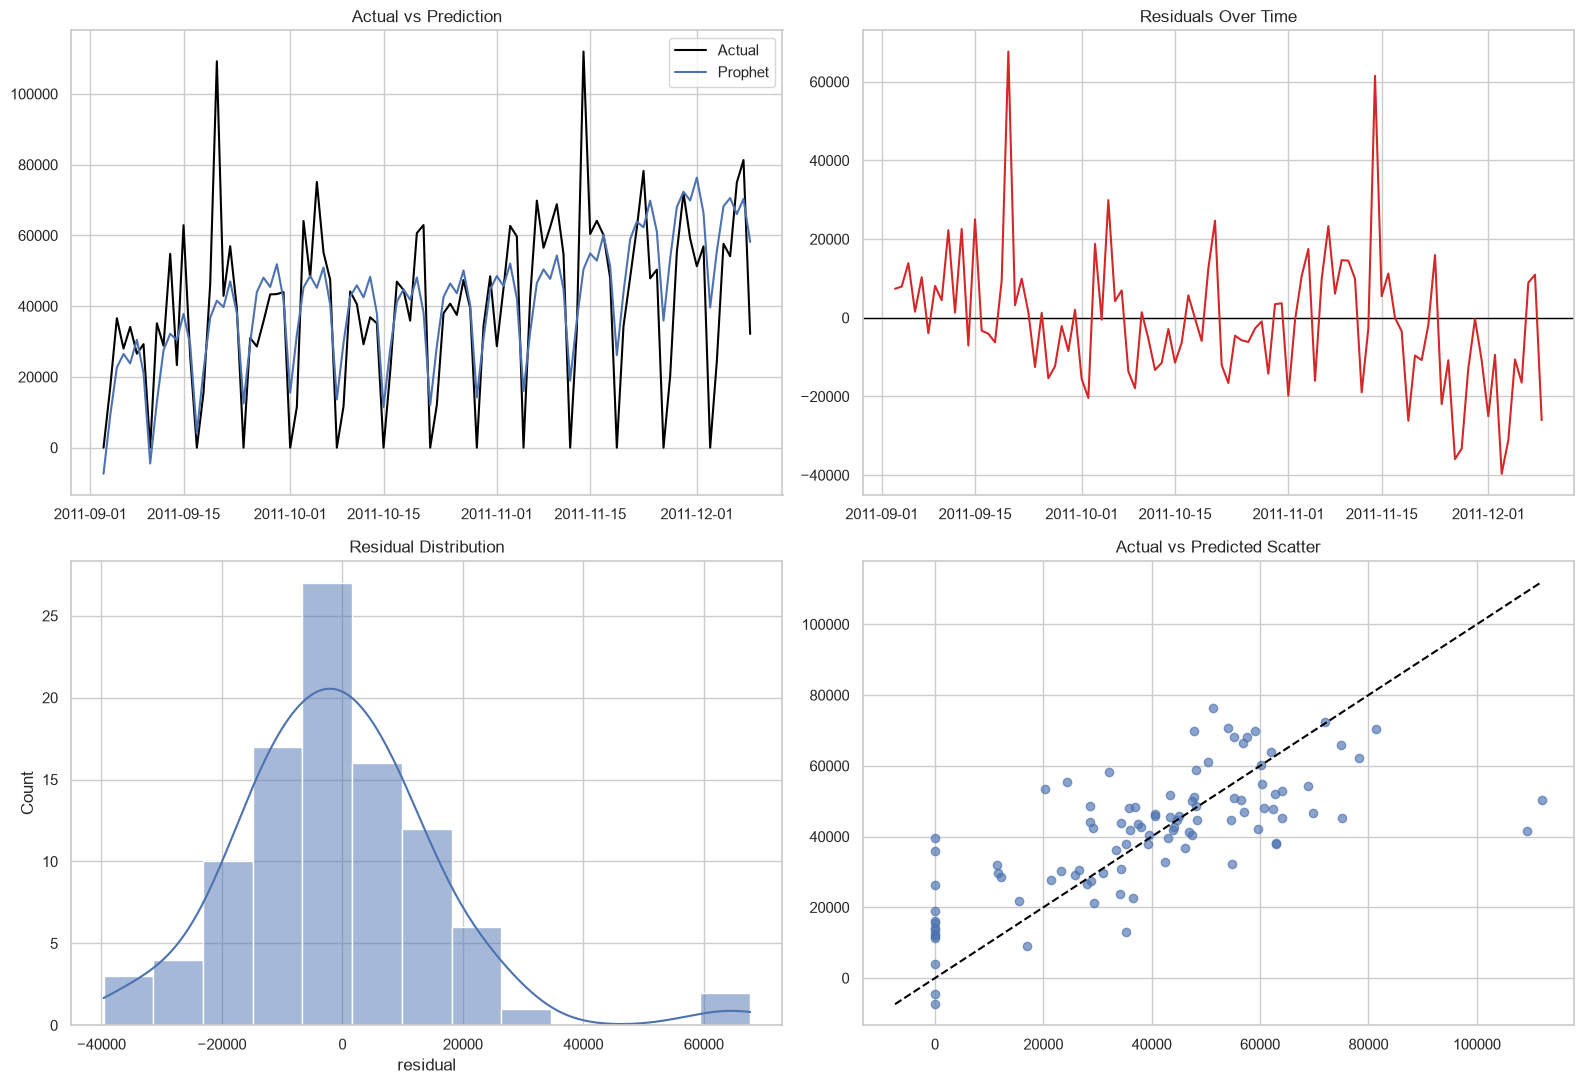

In [10]:
# Residual and prediction diagnostics
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes[0, 0].plot(evaluation_predictions['date'], evaluation_predictions['actual'], label='Actual', color='black')
axes[0, 0].plot(evaluation_predictions['date'], evaluation_predictions['prediction'], label=selected_model)
axes[0, 0].set_title('Actual vs Prediction'); axes[0, 0].legend()
axes[0, 1].axhline(0, color='black', linewidth=1)
axes[0, 1].plot(evaluation_predictions['date'], evaluation_predictions['residual'], color='tab:red')
axes[0, 1].set_title('Residuals Over Time')
sns.histplot(evaluation_predictions['residual'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Residual Distribution')
axes[1, 1].scatter(evaluation_predictions['actual'], evaluation_predictions['prediction'], alpha=.65)
low = min(evaluation_predictions['actual'].min(), evaluation_predictions['prediction'].min())
high = max(evaluation_predictions['actual'].max(), evaluation_predictions['prediction'].max())
axes[1, 1].plot([low, high], [low, high], '--', color='black')
axes[1, 1].set_title('Actual vs Predicted Scatter')
plt.tight_layout(); plt.show()

In [11]:
diagnostics = {
    'mean_residual_bias': float(evaluation_predictions['residual'].mean()),
    'median_residual': float(evaluation_predictions['residual'].median()),
    'residual_std': float(evaluation_predictions['residual'].std(ddof=0)),
    'negative_prediction_count': int((evaluation_predictions['prediction'] < 0).sum()),
    'test_observations': int(len(evaluation_predictions)),
}
pd.Series(diagnostics, name='value')

mean_residual_bias           -1073.658950
median_residual              -1954.193393
residual_std                 16803.798087
negative_prediction_count        2.000000
test_observations               98.000000
Name: value, dtype: float64

In [12]:
# Prophet confidence interval diagnostics
prophet_predictions = pd.read_csv(paths['prophet_predictions'])
lower_column = find_column(prophet_predictions, ['yhat_lower', 'lower'])
upper_column = find_column(prophet_predictions, ['yhat_upper', 'upper'])
prophet_actual = find_column(prophet_predictions, ['net_revenue', 'y', 'actual'])
if lower_column and upper_column and prophet_actual:
    covered = (
        (prophet_predictions[prophet_actual] >= prophet_predictions[lower_column])
        & (prophet_predictions[prophet_actual] <= prophet_predictions[upper_column])
    )
    interval_coverage_pct = covered.mean() * 100
    average_interval_width = (prophet_predictions[upper_column] - prophet_predictions[lower_column]).mean()
    print('Interval coverage %:', round(interval_coverage_pct, 2))
    print('Average interval width:', round(average_interval_width, 2))
else:
    interval_coverage_pct = np.nan
    average_interval_width = np.nan
    print('Prophet interval columns were not found.')

Interval coverage %: 69.39
Average interval width: 29485.98


In [13]:
# Decision summary and saved outputs
selected_validation = validation_metrics.iloc[0]
selected_test_row = selected_test.iloc[0]
decision = {
    'selected_model': selected_model,
    'selection_rule': 'lowest validation RMSE; MAE tie-breaker',
    'validation_MAE': float(selected_validation['MAE']),
    'validation_RMSE': float(selected_validation['RMSE']),
    'test_MAE': float(selected_test_row['MAE']),
    'test_RMSE': float(selected_test_row['RMSE']),
    'test_MAPE_pct': float(selected_test_row['MAPE_pct']),
    'test_R2': float(selected_test_row['R2']),
    'validation_RMSE_improvement_vs_naive_pct': float(
        validation_metrics.iloc[0]['RMSE_improvement_vs_naive_pct']
    ),
    'prophet_interval_coverage_pct': None if np.isnan(interval_coverage_pct) else float(interval_coverage_pct),
    'prophet_average_interval_width': None if np.isnan(average_interval_width) else float(average_interval_width),
    **diagnostics,
}
decision

{'selected_model': 'Prophet',
 'selection_rule': 'lowest validation RMSE; MAE tie-breaker',
 'validation_MAE': 8096.651652607401,
 'validation_RMSE': 10787.230116803275,
 'test_MAE': 12334.488431530392,
 'test_RMSE': 16838.06324087969,
 'test_MAPE_pct': 29.92109202513373,
 'test_R2': 0.5027893748132999,
 'validation_RMSE_improvement_vs_naive_pct': 41.44421004695984,
 'prophet_interval_coverage_pct': 69.38775510204081,
 'prophet_average_interval_width': 29485.976784628238,
 'mean_residual_bias': -1073.6589495067954,
 'median_residual': -1954.1933925367957,
 'residual_std': 16803.798087456533,
 'negative_prediction_count': 2,
 'test_observations': 98}

In [14]:
validation_metrics.to_csv(OUTPUT_DIR / 'validation_model_comparison.csv', index=False)
test_metrics.to_csv(OUTPUT_DIR / 'test_model_comparison.csv', index=False)
evaluation_predictions.to_csv(OUTPUT_DIR / 'selected_model_test_predictions.csv', index=False)
(OUTPUT_DIR / 'final_model_decision.json').write_text(json.dumps(decision, indent=2), encoding='utf-8')

summary = pd.DataFrame([
    {'criterion': 'Selected model', 'value': selected_model},
    {'criterion': 'Validation RMSE', 'value': round(decision['validation_RMSE'], 3)},
    {'criterion': 'Test RMSE', 'value': round(decision['test_RMSE'], 3)},
    {'criterion': 'Improvement vs Naive (%)', 'value': round(decision['validation_RMSE_improvement_vs_naive_pct'], 2)},
])
summary.to_csv(OUTPUT_DIR / 'final_model_summary.csv', index=False)
display(summary)
print('completed successfully.')

,criterion,value
0,Selected model,Prophet
1,Validation RMSE,10787.23
2,Test RMSE,16838.063
3,Improvement vs Naive (%),41.44


completed successfully.


## Completion rules

This complete only when every model has validation metrics, the selected model has test metrics and predictions, residuals show no unacceptable systematic bias, and the final decision files are saved.